# Data Visualization with Matplotlib & Seaborn
**Dataset:** seaborn `tips` (244 restaurant meals: total_bill, tip, sex, smoker, day, time, size)

**Four questions I want to answer**
1. How are bills distributed?
2. Do tips differ by day?
3. Does a bigger bill mean a bigger tip?
4. Which numbers move together?

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["text.parse_math"] = False   # so $ signs print normally
OUT = "charts"
os.makedirs(OUT, exist_ok=True)

# One colour-blind-friendly palette used everywhere (no red + green together)
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.0)

tips = sns.load_dataset("tips")
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100   # tip as % of bill
tips["day"] = pd.Categorical(tips["day"], ["Thur", "Fri", "Sat", "Sun"], ordered=True)
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


## Step 0: Know the data first

In [2]:
print(tips.shape)
print(tips.isna().sum().sum(), "missing values")
tips.describe()

(244, 8)
0 missing values


,total_bill,tip,size,tip_pct
count,244.000000,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672,16.080258
std,8.902412,1.383638,0.951100,6.107220
min,3.070000,1.000000,1.000000,3.563814
25%,13.347500,2.000000,2.000000,12.912736
50%,17.795000,2.900000,2.000000,15.476977
75%,24.127500,3.562500,3.000000,19.147549
max,50.810000,10.000000,6.000000,71.034483


## Chart 1: Histogram (one number -> distribution)

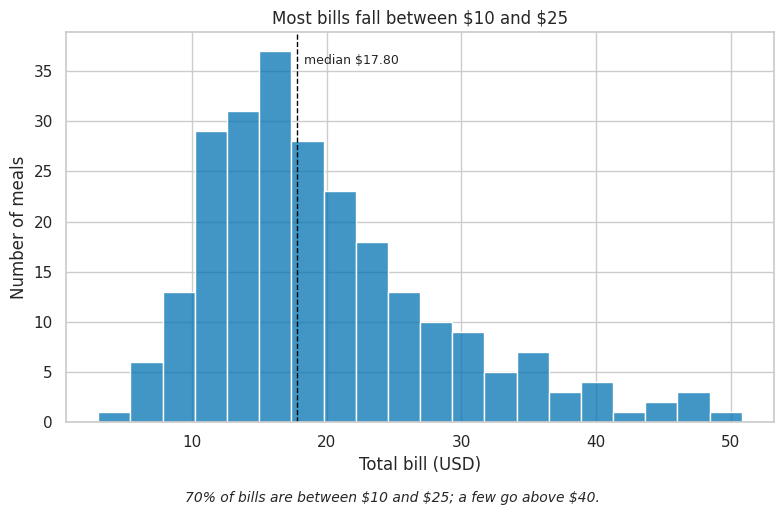

Takeaway: 70% of bills are between $10 and $25; a few go above $40.


In [3]:
share_10_25 = tips["total_bill"].between(10, 25).mean() * 100
t1 = f"{share_10_25:.0f}% of bills are between $10 and $25; a few go above $40."

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(tips["total_bill"], bins=20, ax=ax)
ax.axvline(tips["total_bill"].median(), color="black", ls="--", lw=1)
ax.text(tips["total_bill"].median() + 0.5, ax.get_ylim()[1] * 0.92,
        f"median ${tips['total_bill'].median():.2f}", fontsize=9)
ax.set(title="Most bills fall between $10 and $25",
       xlabel="Total bill (USD)", ylabel="Number of meals")
fig.text(0.5, -0.02, t1, ha="center", fontsize=10, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT}/1_histogram_bills.png", dpi=150, bbox_inches="tight")
plt.show()
print("Takeaway:", t1)

## Chart 2: Box plot (compare groups)

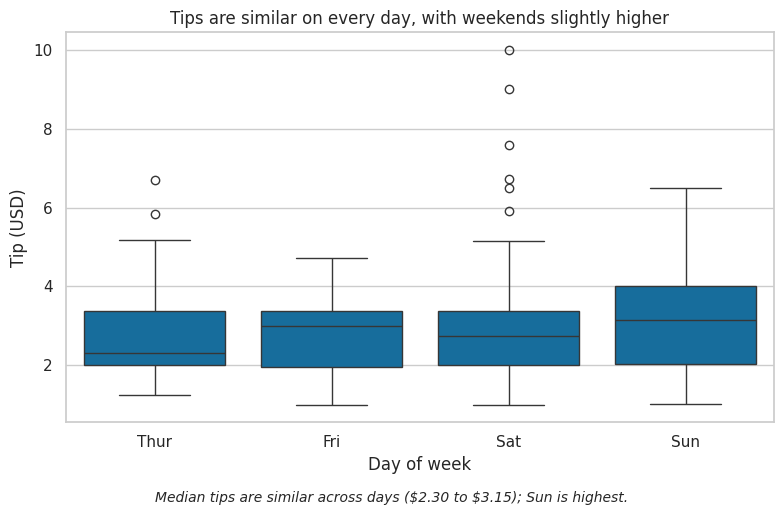

Takeaway: Median tips are similar across days ($2.30 to $3.15); Sun is highest.


In [4]:
med = tips.groupby("day", observed=True)["tip"].median()
best = med.idxmax()
t2 = (f"Median tips are similar across days (${med.min():.2f} to ${med.max():.2f}); "
      f"{best} is highest.")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip", ax=ax)
ax.set(title="Tips are similar on every day, with weekends slightly higher",
       xlabel="Day of week", ylabel="Tip (USD)")
fig.text(0.5, -0.02, t2, ha="center", fontsize=10, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT}/2_boxplot_tip_by_day.png", dpi=150, bbox_inches="tight")
plt.show()
print("Takeaway:", t2)

## Chart 3: Bar chart (average per group, axis starts at zero)

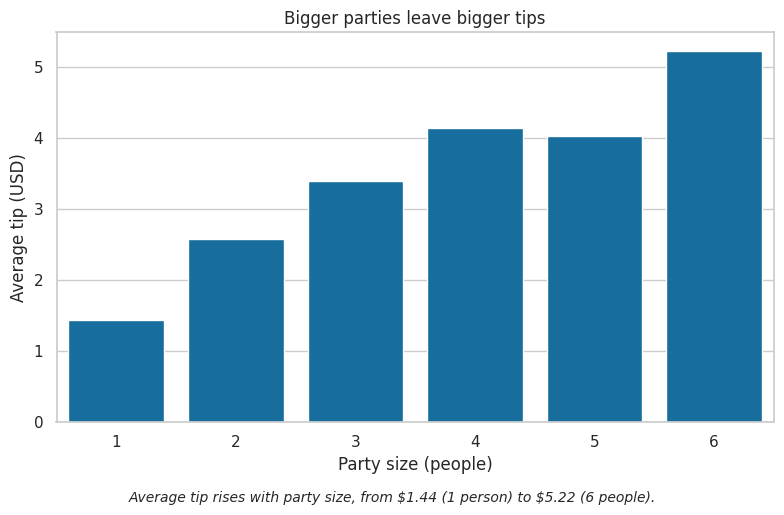

Takeaway: Average tip rises with party size, from $1.44 (1 person) to $5.22 (6 people).


In [5]:
avg_size = tips.groupby("size")["tip"].mean().reset_index()
t3 = "Average tip rises with party size, from ${:.2f} (1 person) to ${:.2f} (6 people).".format(
    avg_size["tip"].iloc[0], avg_size["tip"].iloc[-1])

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=tips, x="size", y="tip", errorbar=None, ax=ax, color=sns.color_palette()[0])
ax.set_ylim(0, None)   # honest: bars start at zero
ax.set(title="Bigger parties leave bigger tips",
       xlabel="Party size (people)", ylabel="Average tip (USD)")
fig.text(0.5, -0.02, t3, ha="center", fontsize=10, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT}/3_bar_tip_by_size.png", dpi=150, bbox_inches="tight")
plt.show()
print("Takeaway:", t3)

## Chart 4: Scatter plot (two numbers), colour = time of day

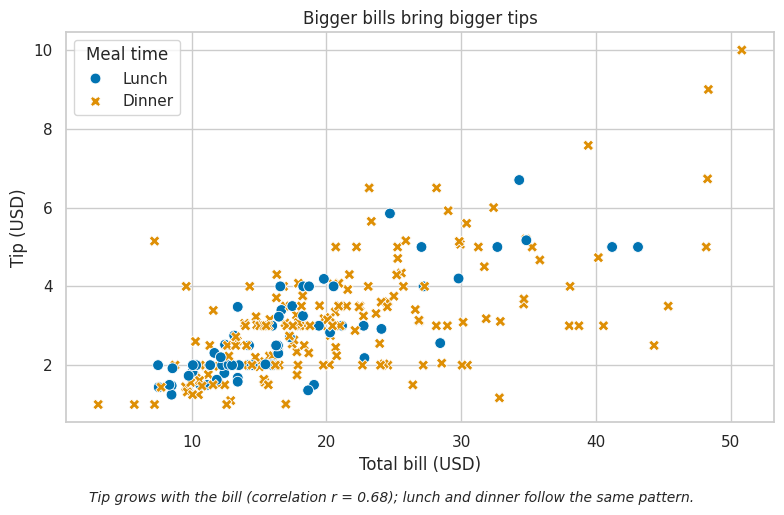

Takeaway: Tip grows with the bill (correlation r = 0.68); lunch and dinner follow the same pattern.


In [6]:
r = tips["total_bill"].corr(tips["tip"])
t4 = f"Tip grows with the bill (correlation r = {r:.2f}); lunch and dinner follow the same pattern."

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="time", s=60, ax=ax)
ax.set(title="Bigger bills bring bigger tips",
       xlabel="Total bill (USD)", ylabel="Tip (USD)")
ax.legend(title="Meal time")
fig.text(0.5, -0.02, t4, ha="center", fontsize=10, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT}/4_scatter_bill_vs_tip.png", dpi=150, bbox_inches="tight")
plt.show()
print("Takeaway:", t4)

## Chart 5: Correlation heatmap

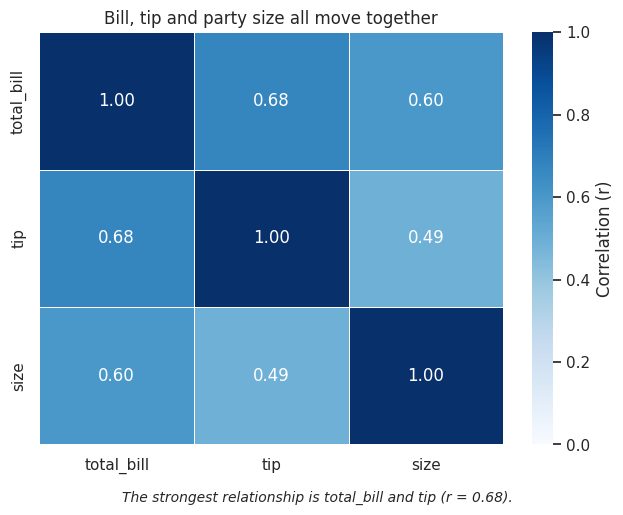

Takeaway: The strongest relationship is total_bill and tip (r = 0.68).


In [7]:
corr = tips[["total_bill", "tip", "size"]].corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top_pair = pairs.abs().idxmax()
t5 = (f"The strongest relationship is {top_pair[0]} and {top_pair[1]} "
      f"(r = {corr.loc[top_pair]:.2f}).")

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation (r)"}, ax=ax)
ax.set_title("Bill, tip and party size all move together")
fig.text(0.5, -0.02, t5, ha="center", fontsize=10, style="italic")
plt.tight_layout()
plt.savefig(f"{OUT}/5_heatmap_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Takeaway:", t5)

## Dashboard: four charts in a 2x2 grid

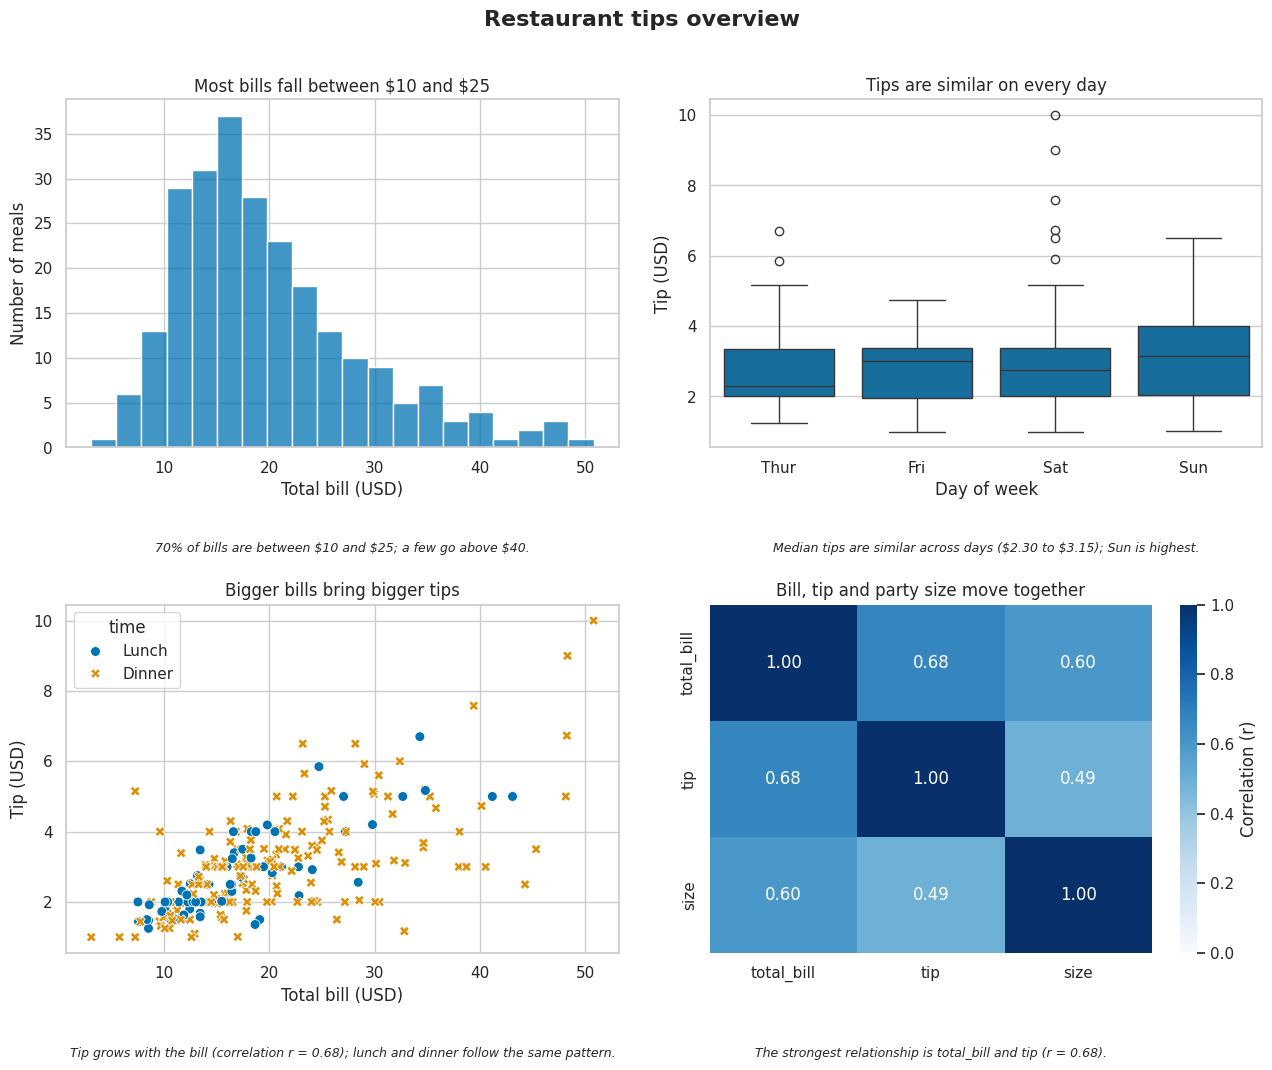

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

sns.histplot(tips["total_bill"], bins=20, ax=axes[0, 0])
axes[0, 0].set(title="Most bills fall between $10 and $25",
               xlabel="Total bill (USD)", ylabel="Number of meals")

sns.boxplot(data=tips, x="day", y="tip", ax=axes[0, 1])
axes[0, 1].set(title="Tips are similar on every day",
               xlabel="Day of week", ylabel="Tip (USD)")

sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="time", s=50, ax=axes[1, 0])
axes[1, 0].set(title="Bigger bills bring bigger tips",
               xlabel="Total bill (USD)", ylabel="Tip (USD)")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Correlation (r)"}, ax=axes[1, 1])
axes[1, 1].set_title("Bill, tip and party size move together")

# takeaway sentence under each chart
for ax, text in zip(axes.flat, [t1, t2, t4, t5]):
    ax.text(0.5, -0.27, text, transform=ax.transAxes, ha="center", va="top",
            fontsize=9, style="italic", wrap=True)

fig.suptitle("Restaurant tips overview", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"{OUT}/tips_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## Honesty check
- Bar chart starts at zero.
- Nothing cut off (`tight_layout` + `bbox_inches="tight"`).
- One colour-blind-friendly palette; colour means *meal time* in the scatter plot.
- Correlation is not causation: a bigger bill does not *cause* a bigger tip, bigger parties just order more and tip more.